# 07 - RQ1: robustness across seeds, significance and error audit
Run after `06_thresholds.ipynb`. Nothing here changes the frozen thresholds of the main run (`results/rq1/calibration.json`).

1. **Paired bootstrap** over the 2,067 test comments (10,000 resamples, seed 42): confidence intervals for the differences between the three decoders on the same resample.
2. **Two extra training seeds** (43, 44) of the same PhoBERT configuration. Each seed gets its own thresholds, fitted on its own validation scores and frozen before its test file is read (`results/rq1/seeds/<run>/`).
3. **Error audit** (brief, part C): error counts, decisions flipped by the tuned thresholds, confused and co-occurring label pairs, under/over-prediction by label cardinality, and a manual audit of 80 sampled cases.

Training the extra seeds needs the GPU (about 25 min each on an RTX 3060 Laptop); everything else runs on the CPU from saved probabilities:
```bash
python -m src.train_phobert --emoji text --loss pw_sqrt --epochs 12 --patience 3 --seed 43 --name phobert_text_pw_sqrt_ep12_seed43
python -m src.train_phobert --emoji text --loss pw_sqrt --epochs 12 --patience 3 --seed 44 --name phobert_text_pw_sqrt_ep12_seed44
```
No comment text is printed or saved. The manual audit was read locally with `python -m src.show_cases --cases results/rq1/error_analysis/cases.csv --group <group>`; only paraphrased notes are stored.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif ROOT.name == 'Deep-Learning':
    ROOT = ROOT / 'ati_final'
assert (ROOT / 'src' / 'rq1_audit.py').exists(), 'Run from ati_final or its notebooks directory'
sys.path.insert(0, str(ROOT))
from src import rq1_audit as audit
OUT = ROOT / 'results' / 'rq1'
pd.set_option('display.width', 200)

## 1. Paired bootstrap on the test set (main run, seed 42)
A difference is called reliable only if its 95% interval excludes 0. `share_resamples_a_better` is the fraction of resamples in which the first decoder wins (lower is better for Hamming loss).

In [2]:
boot = audit.bootstrap()
display(boot[boot.scope == 'all'].round(4))
display(boot[(boot.scope != 'all') & (boot.metric == 'macro_f1')].round(4))

,comparison,scope,metric,observed_delta,ci95_low,ci95_high,share_resamples_a_better,n_boot
0,global - fixed,all,macro_f1,0.0043,-0.0007,0.0091,0.9551,10000
1,global - fixed,all,micro_f1,0.0035,-0.0010,0.0081,0.9368,10000
2,global - fixed,all,hamming_loss,-0.0037,-0.0044,-0.0029,1.0000,10000
12,per_label - fixed,all,macro_f1,0.0060,-0.0017,0.0134,0.9344,10000
13,per_label - fixed,all,micro_f1,0.0021,-0.0042,0.0082,0.7388,10000
14,per_label - fixed,all,hamming_loss,-0.0031,-0.0041,-0.0020,1.0000,10000
24,per_label - global,all,macro_f1,0.0017,-0.0056,0.0090,0.6720,10000
25,per_label - global,all,micro_f1,-0.0015,-0.0076,0.0047,0.3225,10000
26,per_label - global,all,hamming_loss,0.0006,-0.0004,0.0016,0.1265,10000


,comparison,scope,metric,observed_delta,ci95_low,ci95_high,share_resamples_a_better,n_boot
3,global - fixed,head,macro_f1,0.0004,-0.0064,0.0071,0.5430,10000
6,global - fixed,mid,macro_f1,0.0080,-0.0002,0.0157,0.9728,10000
9,global - fixed,tail,macro_f1,0.0046,-0.0064,0.0151,0.8010,10000
15,per_label - fixed,head,macro_f1,0.0139,0.0048,0.0226,0.9982,10000
18,per_label - fixed,mid,macro_f1,0.0061,-0.0069,0.0190,0.8230,10000
21,per_label - fixed,tail,macro_f1,-0.0041,-0.0221,0.0130,0.3280,10000
27,per_label - global,head,macro_f1,0.0135,0.0057,0.0212,0.9995,10000
30,per_label - global,mid,macro_f1,-0.0019,-0.0155,0.0116,0.3906,10000
33,per_label - global,tail,macro_f1,-0.0087,-0.0255,0.0078,0.1472,10000


## 2. Three training seeds
Same configuration as the Midterm model (emoji to text, BCE with square-root positive weight, 12 epochs, patience 3). Standard deviations use ddof = 1 over 3 seeds.

In [3]:
per_seed, agg, deltas, stab = audit.seeds()
display(per_seed.round(4))
display(agg.round(4))
display(deltas.round(4))
# Threshold overfitting check: does each label's validation gain (per-label vs 0.5) transfer to test?
display(pd.read_csv(OUT / 'tables' / 'seed_gain_transfer.csv').round(3))

,seed,run,strategy,global_threshold,test_macro_f1,test_micro_f1,test_hamming_loss,test_mean_predicted_cardinality,gap_val_minus_test_macro_f1,test_macro_f1_head,test_macro_f1_mid,test_macro_f1_tail
0,42,phobert_text_pw_sqrt_ep12,fixed,0.575,0.6082,0.6240,0.0583,2.4359,-0.0051,0.6345,0.6030,0.5817
1,42,phobert_text_pw_sqrt_ep12,global,0.575,0.6125,0.6276,0.0546,2.2003,-0.0048,0.6349,0.6110,0.5864
2,42,phobert_text_pw_sqrt_ep12,per_label,0.575,0.6142,0.6261,0.0552,2.2269,0.0116,0.6484,0.6091,0.5777
3,43,phobert_text_pw_sqrt_ep12_seed43,fixed,0.600,0.6092,0.6240,0.0580,2.4127,0.0005,0.6413,0.6087,0.5699
4,43,phobert_text_pw_sqrt_ep12_seed43,global,0.600,0.6138,0.6298,0.0533,2.1243,0.0013,0.6469,0.6115,0.5752
5,43,phobert_text_pw_sqrt_ep12_seed43,per_label,0.600,0.6122,0.6255,0.0535,2.0948,0.0184,0.6479,0.6063,0.5751
6,44,phobert_text_pw_sqrt_ep12_seed44,fixed,0.600,0.5934,0.6090,0.0611,2.4669,0.0051,0.6281,0.5933,0.5502
7,44,phobert_text_pw_sqrt_ep12_seed44,global,0.600,0.6032,0.6188,0.0553,2.1524,0.0009,0.6356,0.6047,0.5608
8,44,phobert_text_pw_sqrt_ep12_seed44,per_label,0.600,0.6081,0.6206,0.0565,2.2637,0.0169,0.6452,0.5995,0.5725


,strategy,n_seeds,test_macro_f1_mean,test_macro_f1_std,test_micro_f1_mean,test_micro_f1_std,test_hamming_loss_mean,test_hamming_loss_std,test_mean_predicted_cardinality_mean,test_mean_predicted_cardinality_std,gap_val_minus_test_macro_f1_mean,gap_val_minus_test_macro_f1_std,test_macro_f1_head_mean,test_macro_f1_head_std,test_macro_f1_mid_mean,test_macro_f1_mid_std,test_macro_f1_tail_mean,test_macro_f1_tail_std
0,fixed,3,0.6036,0.0088,0.6190,0.0087,0.0591,0.0017,2.4385,0.0272,0.0002,0.0052,0.6346,0.0066,0.6017,0.0078,0.5673,0.0159
1,global,3,0.6098,0.0058,0.6254,0.0058,0.0544,0.0010,2.1590,0.0384,-0.0009,0.0034,0.6391,0.0067,0.6091,0.0038,0.5741,0.0128
2,per_label,3,0.6115,0.0031,0.6241,0.0030,0.0551,0.0015,2.1951,0.0888,0.0157,0.0035,0.6472,0.0017,0.6050,0.0049,0.5751,0.0026


,global - fixed,per_label - fixed,per_label - global
seed,,,
42,0.0043,0.0060,0.0017
43,0.0045,0.0030,-0.0015
44,0.0098,0.0147,0.0049
mean,0.0062,0.0079,0.0017
std,0.0031,0.0061,0.0032


,seed,run,spearman_val_gain_vs_test_gain,labels_val_gain_positive,labels_test_gain_positive,labels_test_gain_negative,mean_val_gain,mean_test_gain
0,42,phobert_text_pw_sqrt_ep12,0.086,27,14,12,0.023,0.006
1,43,phobert_text_pw_sqrt_ep12_seed43,-0.184,26,13,13,0.021,0.003
2,44,phobert_text_pw_sqrt_ep12_seed44,0.305,26,20,6,0.026,0.015


,tier,seed42,seed43,seed44,mean,std,range
label,,,,,,,
amusement,head,0.500,0.625,0.525,0.550,0.066,0.125
excitement,mid,0.525,0.625,0.700,0.617,0.088,0.175
joy,head,0.650,0.675,0.550,0.625,0.066,0.125
love,head,0.800,0.700,0.675,0.725,0.066,0.125
desire,mid,0.400,0.600,0.700,0.567,0.153,0.300
optimism,head,0.650,0.750,0.775,0.725,0.066,0.125
caring,head,0.750,0.750,0.625,0.708,0.072,0.125
pride,mid,0.625,0.775,0.575,0.658,0.104,0.200
admiration,mid,0.475,0.675,0.550,0.567,0.101,0.200


Mean range of a label threshold across seeds: 0.175


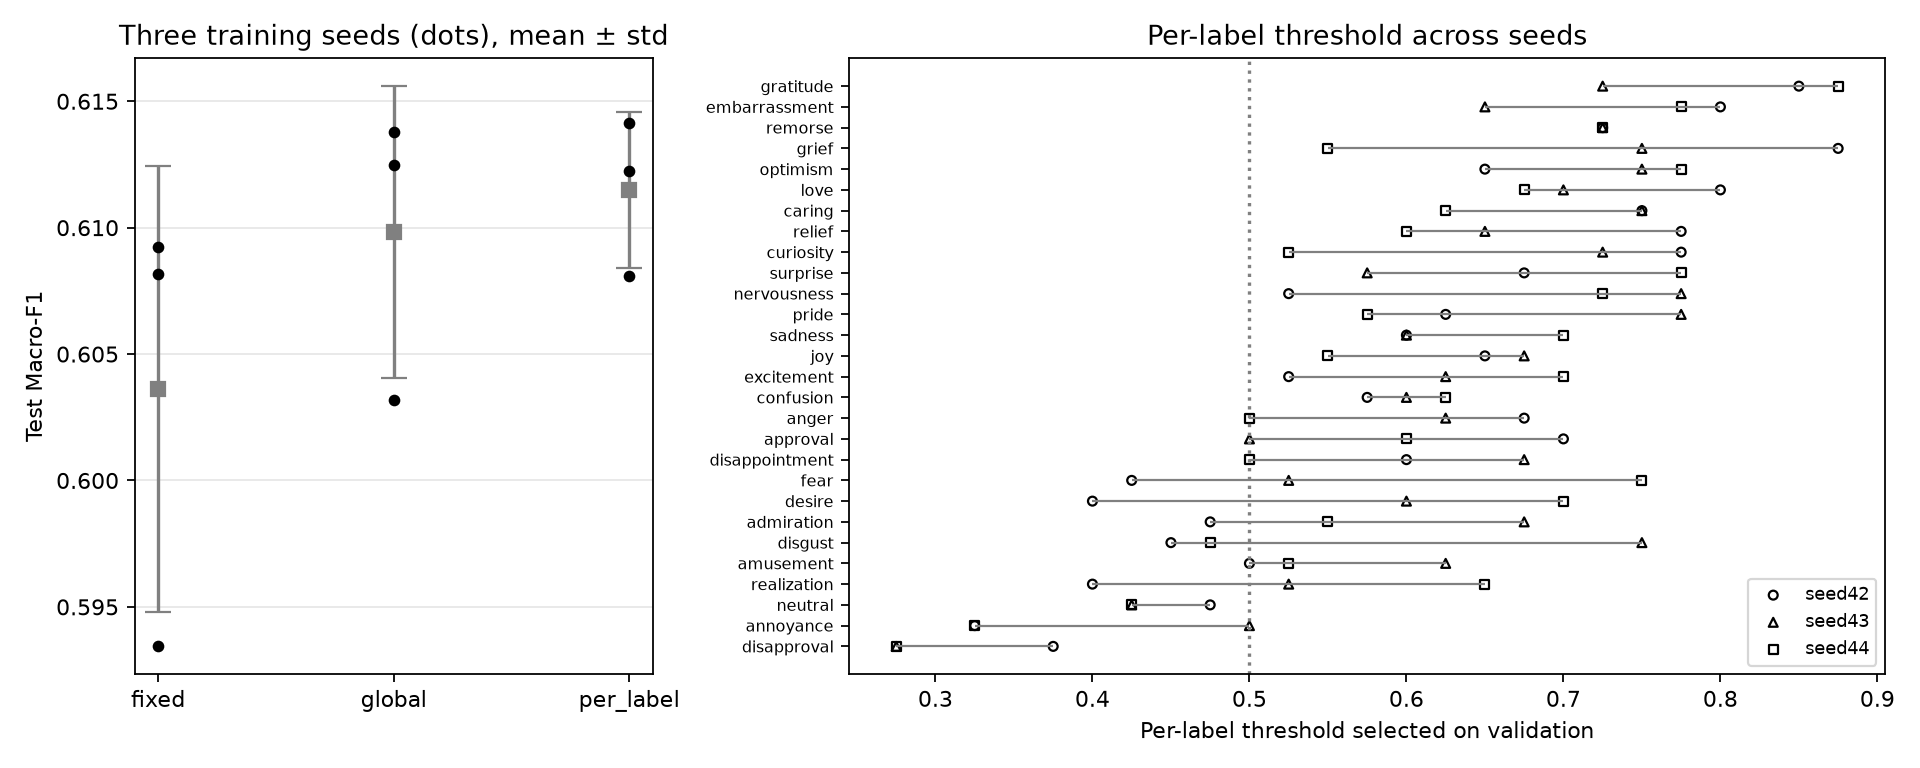

In [4]:
display(stab.round(3))
print('Mean range of a label threshold across seeds:', round(float(stab['range'].mean()), 3))
display(Image(filename=str(OUT / 'figures' / 'seed_robustness.png')))

## 3. Error audit (main run, test set)
### 3.1 Quantitative
The case sample below is drawn with seed 42 before any text is read and excludes the 70 comments already read in the Midterm audit.

In [5]:
counts, flips, pairs, cases = audit.errors()
display(counts.groupby('strategy')[['tp', 'fp', 'fn']].sum())
display(counts.groupby(['strategy', 'tier'])[['tp', 'fp', 'fn']].sum())
display(flips.groupby('comparison')[['fn_recovered', 'fn_introduced', 'fp_removed', 'fp_introduced', 'net_correct_decisions']].sum())

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,tp,fp,fn
strategy,,,
fixed,2801,2234,1141
global,2664,1884,1278
per_label,2675,1928,1267


tp    fp   fn
strategy  tier                 
fixed     head  1659  1210  569
          mid    687   596  336
          tail   455   428  236
global    head  1569  1032  659
          mid    661   491  362
          tail   434   361  257
per_label head  1602  1025  626
          mid    662   568  361
          tail   411   335  280

,fn_recovered,fn_introduced,fp_removed,fp_introduced,net_correct_decisions
comparison,,,,,
global vs fixed,0,137,350,0,213
per_label vs fixed,68,194,491,185,180
per_label vs global,137,126,279,323,-33


,label,tier,threshold_a,fn_recovered,fn_introduced,fp_removed,fp_introduced,net_correct_decisions
26,disapproval,mid,0.375,11,0,0,55,-44
25,annoyance,head,0.325,29,0,0,70,-41
12,realization,tail,0.400,4,0,0,19,-15
23,disgust,head,0.450,5,0,0,14,-9
8,admiration,mid,0.475,0,0,0,4,-4
16,fear,tail,0.425,3,0,0,6,-3
4,desire,mid,0.400,12,0,0,15,-3
7,pride,mid,0.625,0,6,4,0,-2
0,amusement,head,0.500,0,0,0,0,0
18,remorse,tail,0.725,0,11,11,0,0


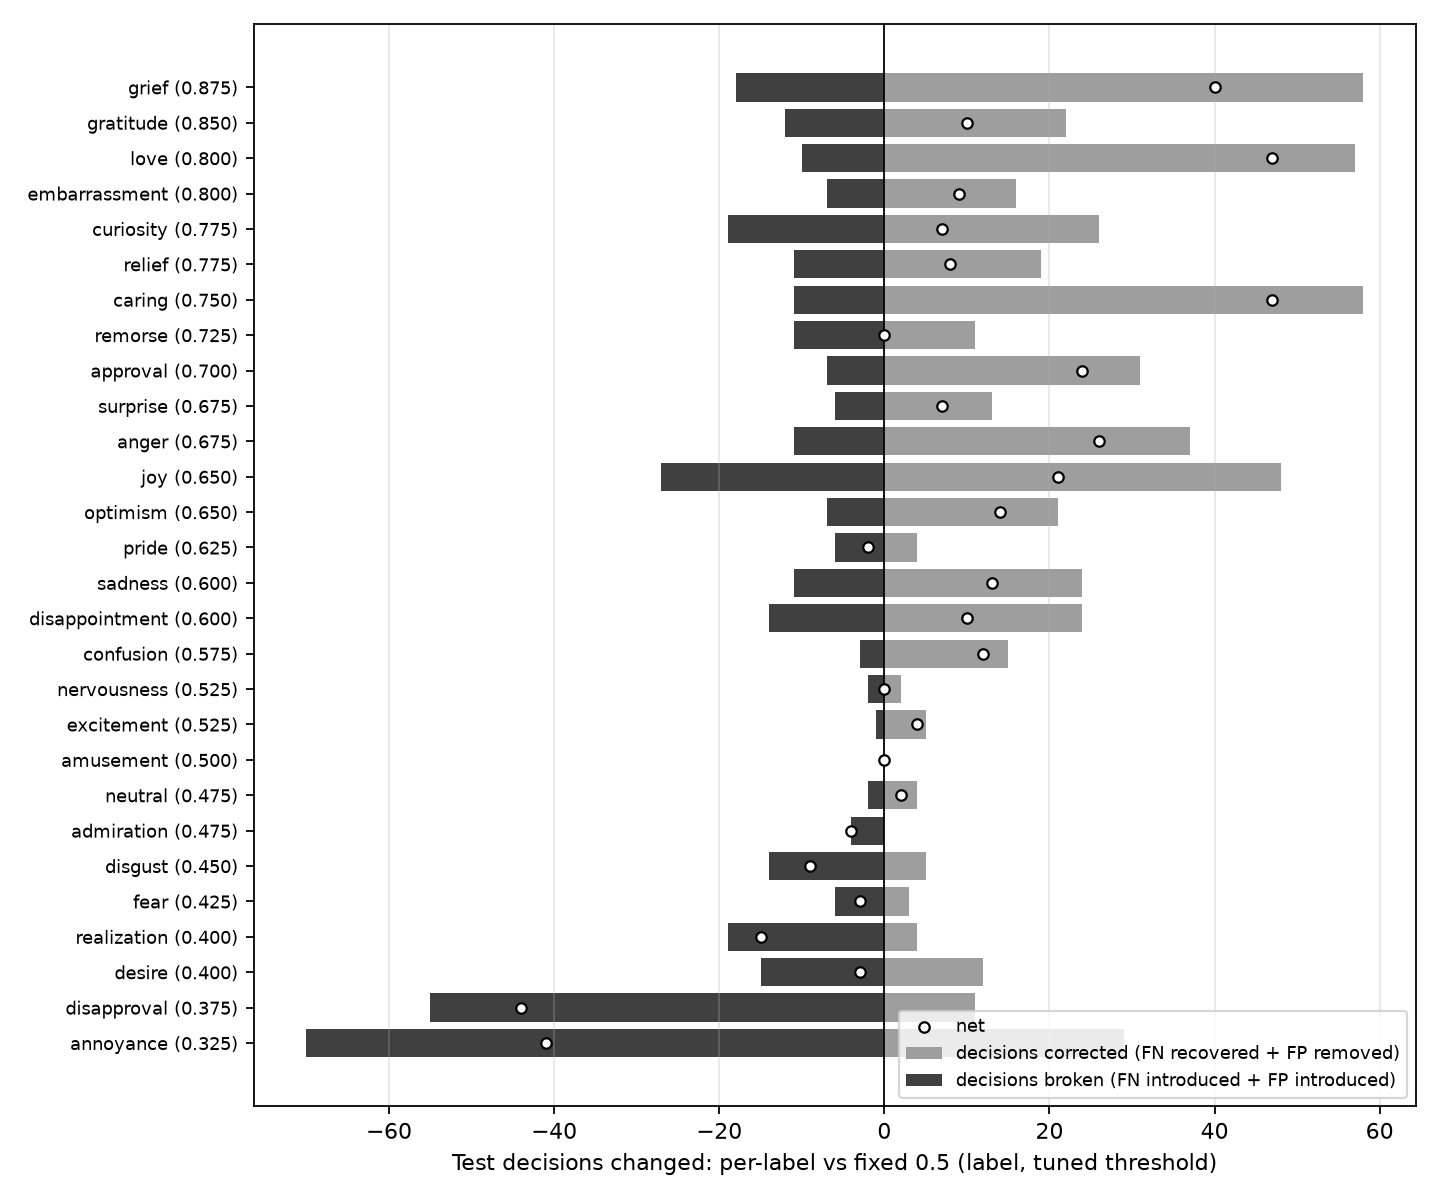

In [6]:
d = flips[flips.comparison == 'per_label vs fixed'].sort_values('net_correct_decisions')
display(d[['label', 'tier', 'threshold_a', 'fn_recovered', 'fn_introduced', 'fp_removed', 'fp_introduced', 'net_correct_decisions']])
display(Image(filename=str(OUT / 'figures' / 'decision_flips.png')))

In [7]:
# Confused pairs: gold label i missed while label j is predicted without gold support in the same comment.
# Spurious companions: label i correct, label j added. phi_train is computed from TRAIN labels only.
for kind in ['missed_i_predicted_j', 'correct_i_spurious_j']:
    for s in ['fixed', 'per_label']:
        print(kind, '|', s)
        display(pairs[(pairs.kind == kind) & (pairs.strategy == s)].head(10))

missed_i_predicted_j | fixed


,strategy,kind,label_i,label_j,n_comments,phi_train
473,fixed,missed_i_predicted_j,annoyance,sadness,21,-0.124
430,fixed,missed_i_predicted_j,disgust,disapproval,18,0.016
382,fixed,missed_i_predicted_j,disappointment,disapproval,17,-0.040
475,fixed,missed_i_predicted_j,annoyance,disgust,16,0.077
476,fixed,missed_i_predicted_j,annoyance,anger,14,0.247
357,fixed,missed_i_predicted_j,disappointment,amusement,13,-0.096
403,fixed,missed_i_predicted_j,sadness,annoyance,13,-0.124
429,fixed,missed_i_predicted_j,disgust,annoyance,12,0.077
472,fixed,missed_i_predicted_j,annoyance,disappointment,12,0.052
498,fixed,missed_i_predicted_j,disapproval,disgust,12,0.016


missed_i_predicted_j | per_label


,strategy,kind,label_i,label_j,n_comments,phi_train
2214,per_label,missed_i_predicted_j,disgust,disapproval,21,0.016
2167,per_label,missed_i_predicted_j,disappointment,disapproval,18,-0.040
2231,per_label,missed_i_predicted_j,anger,annoyance,17,0.247
2187,per_label,missed_i_predicted_j,sadness,annoyance,16,-0.124
2166,per_label,missed_i_predicted_j,disappointment,annoyance,15,0.052
2232,per_label,missed_i_predicted_j,anger,disapproval,15,0.074
2253,per_label,missed_i_predicted_j,annoyance,sadness,15,-0.124
2298,per_label,missed_i_predicted_j,neutral,annoyance,15,-0.073
2144,per_label,missed_i_predicted_j,disappointment,amusement,14,-0.096
2067,per_label,missed_i_predicted_j,curiosity,annoyance,13,-0.071


correct_i_spurious_j | fixed


,strategy,kind,label_i,label_j,n_comments,phi_train
909,fixed,correct_i_spurious_j,annoyance,anger,66,0.247
529,fixed,correct_i_spurious_j,amusement,joy,64,0.155
910,fixed,correct_i_spurious_j,annoyance,disapproval,58,0.219
853,fixed,correct_i_spurious_j,sadness,grief,57,0.384
891,fixed,correct_i_spurious_j,anger,disgust,54,0.208
892,fixed,correct_i_spurious_j,anger,annoyance,45,0.247
908,fixed,correct_i_spurious_j,annoyance,disgust,45,0.077
852,fixed,correct_i_spurious_j,sadness,disappointment,35,0.362
607,fixed,correct_i_spurious_j,optimism,caring,33,0.222
574,fixed,correct_i_spurious_j,love,joy,32,0.222


correct_i_spurious_j | per_label


,strategy,kind,label_i,label_j,n_comments,phi_train
2603,per_label,correct_i_spurious_j,annoyance,disapproval,86,0.219
2601,per_label,correct_i_spurious_j,annoyance,disgust,62,0.077
2590,per_label,correct_i_spurious_j,anger,annoyance,58,0.247
2602,per_label,correct_i_spurious_j,annoyance,anger,55,0.247
2589,per_label,correct_i_spurious_j,anger,disgust,51,0.208
2301,per_label,correct_i_spurious_j,amusement,joy,42,0.155
2580,per_label,correct_i_spurious_j,disgust,annoyance,40,0.077
2319,per_label,correct_i_spurious_j,amusement,annoyance,36,-0.055
2591,per_label,correct_i_spurious_j,anger,disapproval,35,0.074
2557,per_label,correct_i_spurious_j,sadness,disappointment,26,0.362


,strategy,cardinality,n_samples,mean_true,mean_pred,share_under,share_equal_count,share_over,share_empty,share_exact_set
0,fixed,1,695,1.000,2.017,0.013,0.348,0.639,0.013,0.296
1,fixed,2,946,2.000,2.506,0.119,0.412,0.468,0.003,0.216
2,fixed,3,360,3.000,2.883,0.333,0.433,0.233,0.000,0.169
3,fixed,>=4,66,4.167,3.394,0.636,0.227,0.136,0.000,0.076
4,global,1,695,1.000,1.801,0.020,0.410,0.570,0.020,0.334
5,global,2,946,2.000,2.274,0.166,0.481,0.353,0.006,0.242
6,global,3,360,3.000,2.636,0.431,0.431,0.139,0.000,0.167
7,global,>=4,66,4.167,2.970,0.788,0.167,0.045,0.000,0.030
8,per_label,1,695,1.000,1.876,0.013,0.422,0.565,0.013,0.353
9,per_label,2,946,2.000,2.307,0.187,0.420,0.393,0.005,0.226


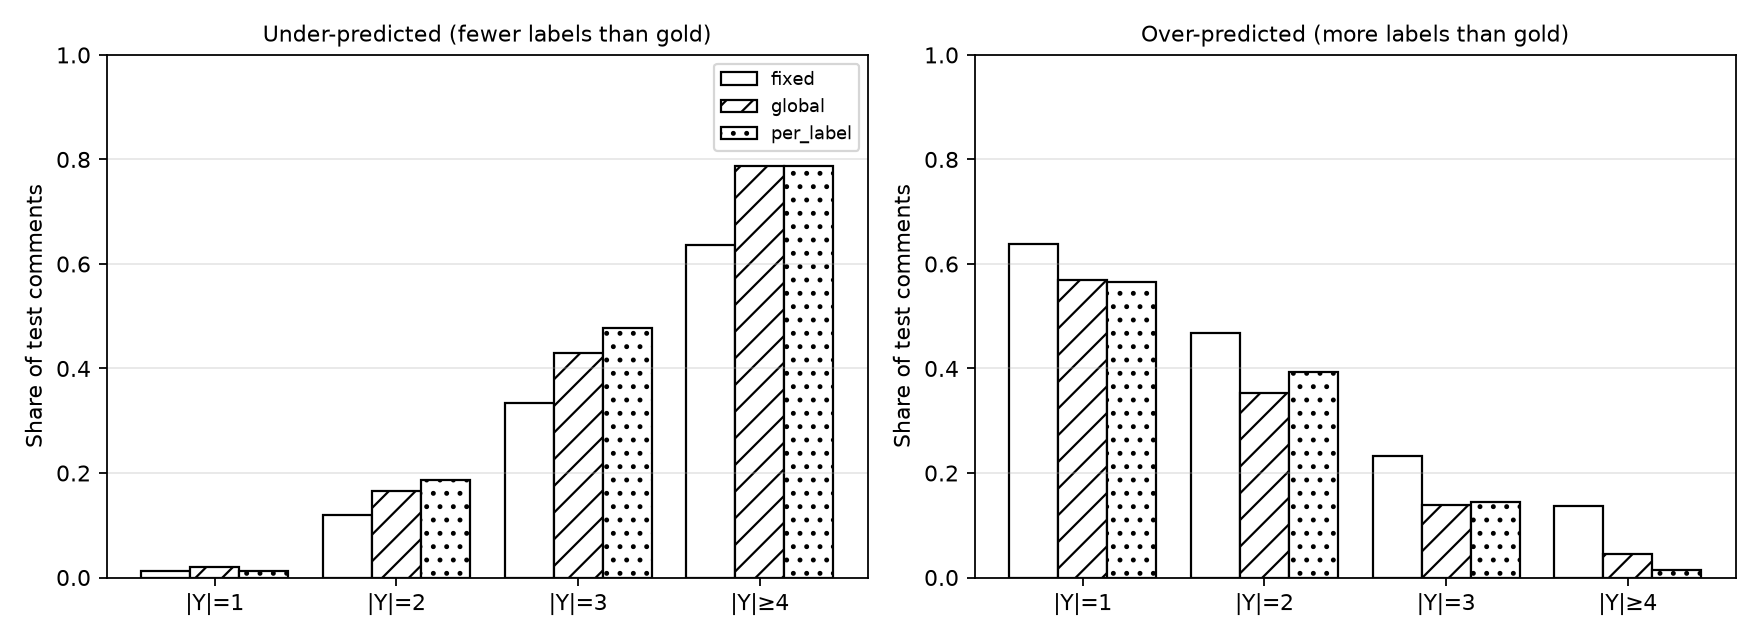

In [8]:
display(pd.read_csv(OUT / 'error_analysis' / 'cardinality_errors.csv').round(3))
display(Image(filename=str(OUT / 'figures' / 'cardinality_errors.png')))

### 3.2 Manual audit of 80 cases
Groups: 20 FN and 20 FP that remain under per-label thresholds (stratified 7 head / 7 mid / 6 tail), 10 FN and 10 FP introduced by per-label tuning, 5 FN recovered and 5 FP removed by it, and 10 comments with at least four gold labels. Each case has one primary cause and an optional secondary cause (`annotations.csv`). The coding is a subjective judgement by the group.

In [9]:
display(cases.group.value_counts())
tally, defens = audit.summarize_annotations()
display(tally)
display(pd.read_csv(OUT / 'error_analysis' / 'cause_mentions.csv'))
display(defens)

group
fn_per_label     20
fp_per_label     20
fn_introduced    10
fp_introduced    10
multi_label      10
fn_recovered      5
fp_removed        5
Name: count, dtype: int64

group,fn_per_label,fp_per_label,fn_introduced,fp_introduced,fn_recovered,fp_removed,multi_label,total
cause_primary,,,,,,,,
Decision flipped by the tuned threshold,3,2,10,10,5,5,0,35
Near-synonymous labels,7,5,0,0,0,0,0,12
Mixed or secondary emotions,0,0,0,0,0,0,7,7
"Teencode, dialect or noisy text",4,1,0,0,0,0,1,6
Lexical cue / keyword trap,2,4,0,0,0,0,0,6
Sarcasm or dark humour,1,3,0,0,0,0,1,5
Missing context / very short,2,2,0,0,0,0,0,4
Emoji or emoticon cue,0,2,0,0,0,0,0,2
Questionable or incomplete gold label,0,1,0,0,0,0,1,2


,Unnamed: 0,primary_or_secondary
0,Decision flipped by the tuned threshold,39
1,Near-synonymous labels,20
2,"Teencode, dialect or noisy text",12
3,Mixed or secondary emotions,11
4,Emoji or emoticon cue,10
5,Questionable or incomplete gold label,9
6,Missing context / very short,8
7,Sarcasm or dark humour,8
8,Lexical cue / keyword trap,8
9,Borderline score near 0.5,3


prediction_defensible,no,partly,yes
group,,,
fn_introduced,10,0,0
fn_per_label,11,9,0
fn_recovered,0,0,5
fp_introduced,3,2,5
fp_per_label,9,6,5
fp_removed,0,3,2
multi_label,2,8,0


In [10]:
ann = pd.read_csv(OUT / 'error_analysis' / 'annotations.csv', dtype=str, keep_default_na=False)
with pd.option_context('display.max_colwidth', 200):
    display(ann[['group', 'sample_id', 'label', 'cause_primary', 'cause_secondary', 'prediction_defensible', 'note']])

,group,sample_id,label,cause_primary,cause_secondary,prediction_defensible,note
0,fn_per_label,you005871,realization,near_synonym,threshold,no,Short surprised self-question with a flushed emoji; model reads it as confusion and loses embarrassment when its threshold rises to 0.80.
1,fn_per_label,3956,joy,threshold,near_synonym,no,Excited reaction to a funny scene; joy scored 0.52 was correct at 0.5 but is cut by the per-label threshold 0.65.
2,fn_per_label,6685,anger,near_synonym,noisy,partly,Crude insult about someone's looks; model chooses disgust and annoyance instead of anger.
3,fn_per_label,24530,optimism,context,,no,Comment tagging a friend and praising an island as still unspoiled and cheap; model reads a complaint or question (curiosity/confusion/annoyance).
4,fn_per_label,6892,disapproval,near_synonym,context,partly,Scolding advice to stop complaining; model reads it as caring advice (optimism/caring) rather than criticism.
...,...,...,...,...,...,...,...
75,multi_label,you002161,,mixed,threshold,partly,Long confession after a family quarrel ending in thanks; fixed finds 3 of 4 while per-label drops gratitude (threshold 0.85).
76,multi_label,tik012624,,mixed,emoji,partly,"Fear of a mother's punishment after breaking a screen; fear/nervousness found, remorse and sadness missed."
77,multi_label,6293,,mixed,,partly,"Wants to adopt a pet but fears not caring for it well; love/desire found, fear/nervousness missed; global also drops desire."
78,multi_label,5081,,sarcasm,emoji,no,Ironic remark that a fine was only five million with a ':v' emoticon; amusement/surprise/anger missed.


## Reading the results
The three decoders share one probability matrix, so the comparison isolates the decision rule. The bootstrap and the seed repeats ask whether the small Macro-F1 differences seen in notebook 06 are larger than resampling and training noise. The flip analysis shows *where* per-label thresholds act: high thresholds on the positive/grief cluster remove many false positives, low thresholds on the annoyance/disapproval cluster add many. The detailed interpretation is in `reports/rq1_final_analysis.md`.